# Лабораторная работа 1

In [17]:
import matplotlib.pyplot as plt

### Рабочий класс

In [18]:
class DataFrame:
    def __init__(self, filepath: str, x_column = 0, y_column = -1):
        self.data = []
        self.headers = []
    
        with open(filepath) as file:
            self.headers = file.readline().split(',')
            self.headers[-1] = self.headers[-1][:-1:]
    
            line = file.readline()
            while line:
                line_data = list(map(float, line.split(',')))
                self.data.append([line_data[x_column], line_data[y_column] / 10**4])
    
                line = file.readline()

    def __str__(self):
        res = ' '.join(self.headers)

        if len(self.data) == 0:
            return res

        str_data = [res]

        for d in self.data:
            d_str = ' '.join(map(str, d))
            str_data.append(d_str)

        return '\n'.join(str_data)


    def size(self):
        if len(self.data) == 0:
            return (0, 0)

        return (len(self.data), len(self.data[0]))

    def min(self):
        res = []

        if len(self.data) == 0:
            return res

        for i in range(len(self.data[0])):
            mini = 10**8

            for d in self.data:
                mini = min(mini, d[i])

            res.append(mini)

        return res

    def max(self):
        res = []
    
        if len(self.data) == 0:
            return res

        for i in range(len(self.data[0])):
            maxi = -10**8

            for d in self.data:
                mini = max(maxi, d[i])

            res.append(mini)

        return res

    def mean(self):
        res = []
            
        if len(self.data) == 0:
            return res

        for i in range(len(self.data[0])):
            s = 0

            for d in self.data:
                s += d[i]

            res.append(s / self.size()[0])

        return res



In [19]:
FILEPATH = 'data/lab1_DS.csv'

df = DataFrame(FILEPATH)
print(str(df))

YearsExperience Salary
1.1 3.9343
1.3 4.6205
1.5 3.7731
2.0 4.3525
2.2 3.9891
2.9 5.6642
3.0 6.015
3.2 5.4445
3.2 6.4445
3.7 5.7189
3.9 6.3218
4.0 5.5794
4.0 5.6957
4.1 5.7081
4.5 6.1111
4.9 6.7938
5.1 6.6029
5.3 8.3088
5.9 8.1363
6.0 9.394
6.8 9.1738
7.1 9.8273
7.9 10.1302
8.2 11.3812
8.7 10.9431
9.0 10.5582
9.5 11.6969
9.6 11.2635
10.3 12.2391
10.5 12.1872
11.2 12.7345
11.5 12.6756
12.3 12.8765
12.9 13.5675
13.5 13.9465


In [20]:
print(f'Size: {df.size()}')
print(f'Columns  {'                 '.join(map(str, list(range(1, df.size()[1] + 1))))}')
print(f'Min      {'               '.join(map(str, df.min()))}')
print(f'Max      {'              '.join(map(str, df.max()))}')
print(f'Mean     {' '.join(map(str, df.mean()))}')


Size: (35, 2)
Columns  1                 2
Min      1.1               3.7731
Max      13.5              13.9465
Mean     6.308571428571429 8.39456


In [21]:
def sqr_per_point(data, w: list[float]):
    mse = []
    n = len(data)

    for i in range(n):
        print(data[i], w[0] + w[1] *data[i][0], (data[i][1] - w[0] - w[1] *data[i][0]))
        mse.append(data[i][1] - w[0] - w[1] *data[i][0])

    return mse

In [22]:
n, m = df.size()
b = (sum([x[0] * x[1] for x in df.data]) / n - sum([x[0] for x in df.data]) * sum([x[1] for x in df.data]) / (n**2)) / (\
    sum([x[0]**2 for x in df.data]) / n - (sum([x[0] for x in df.data]) / n) ** 2)

a = sum([x[1] for x in df.data]) / n - b * sum([x[0] for x in df.data]) / n

line = []
x = df.min()[0]
xm = df.max()[0]
while x < xm:
    line.append((x, a + b*x))
    x += 0.01


In [23]:
mse = sqr_per_point(df.data, [a, b])
print(mse)

[1.1, 3.9343] 3.8464661346300253 0.08783386536997473
[1.3, 4.6205] 4.021104955571275 0.599395044428725
[1.5, 3.7731] 4.195743776512525 -0.4226437765125246
[2.0, 4.3525] 4.632340828865649 -0.27984082886564887
[2.2, 3.9891] 4.806979649806899 -0.8178796498068988
[2.9, 5.6642] 5.4182155231012725 0.2459844768987276
[3.0, 6.015] 5.505534933571898 0.5094650664281022
[3.2, 5.4445] 5.680173754513147 -0.23567375451314776
[3.2, 6.4445] 5.680173754513147 0.7643262454868522
[3.7, 5.7189] 6.116770806866272 -0.3978708068662722
[3.9, 6.3218] 6.291409627807521 0.03039037219247831
[4.0, 5.5794] 6.378729038278147 -0.7993290382781466
[4.0, 5.6957] 6.378729038278147 -0.6830290382781459
[4.1, 5.7081] 6.46604844874877 -0.7579484487487709
[4.5, 6.1111] 6.81532609063127 -0.7042260906312703
[4.9, 6.7938] 7.16460373251377 -0.3708037325137701
[5.1, 6.6029] 7.339242553455019 -0.7363425534550192
[5.3, 8.3088] 7.513881374396269 0.7949186256037306
[5.9, 8.1363] 8.037797837220019 0.09850216277998136
[6.0, 9.394] 8.125

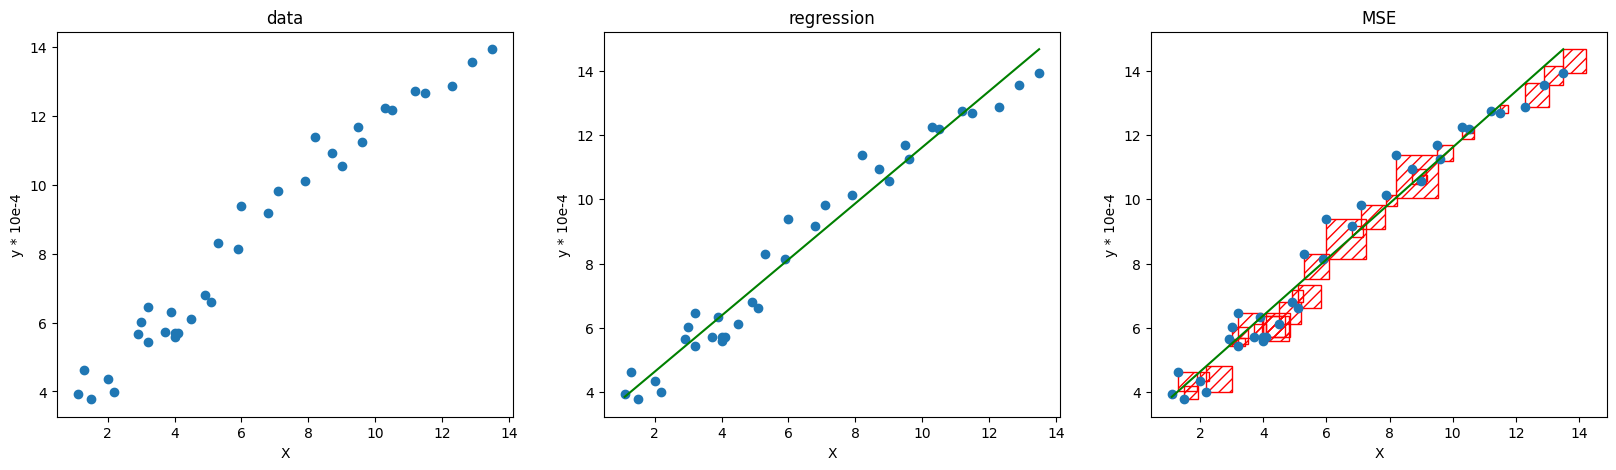

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5))

axes[0].set_title('data')
axes[0].set_xlabel('X')
axes[0].set_ylabel('y * 10e-4')

axes[1].set_title('regression')
axes[1].set_xlabel('X')
axes[1].set_ylabel('y * 10e-4')

axes[2].set_title('MSE')
axes[2].set_xlabel('X')
axes[2].set_ylabel('y * 10e-4')

axes[0].plot([x[0] for x in df.data], [y[1] for y in df.data], 'o')

axes[1].plot([x[0] for x in df.data], [y[1] for y in df.data], 'o')
axes[1].plot([l[0] for l in line], [l[1] for l in line], color='g')

axes[2].plot([x[0] for x in df.data], [y[1] for y in df.data], 'o')
axes[2].plot([l[0] for l in line], [l[1] for l in line], color='g')

for i ,m in enumerate(mse):
    if m <= 0:
        axes[2].add_patch(plt.Rectangle(df.data[i], -m, -m, edgecolor='r', facecolor='none', hatch='///'))
    else:
        axes[2].add_patch(plt.Rectangle((df.data[i][0], df.data[i][1] - m), m, m, edgecolor='r', facecolor='none', hatch='///'))